In [1]:
# PReview Data on a map
import geopandas as gpd
from sqlalchemy import create_engine, text
# Reduce Data and Count initial Rows
engine = create_engine('postgresql://markfinlay:@localhost:5432/osm')

add_column_sql = "ALTER TABLE final_balanced_trail_segments ADD COLUMN IF NOT EXISTS image_data BYTEA;"
with engine.begin() as conn:
    conn.execute(text(add_column_sql))
print("Ensured 'image_data' column exists in 'final_balanced_trail_segments'.")

# Select all rows from trail_segments
query = "SELECT * FROM final_balanced_trail_segments;"

# Load the data into a GeoDataFrame.
trail_segments_gpdf= gpd.read_postgis(query, engine, geom_col='center_geom').to_crs(epsg=3035)

print(len(trail_segments_gpdf))

# Display the first few rows
trail_segments_gpdf.head()

Ensured 'image_data' column exists in 'final_balanced_trail_segments'.
122140


,id,filename,osm_id,surface_group,center_geom,image_data
0,27837,626449758_seg_27837,626449758,asphalt,POINT (3473784.623 3857418.69),"[b'\x93', b'N', b'U', b'M', b'P', b'Y', b'\x01..."
1,29721,23109804_seg_29721,23109804,asphalt,POINT (3613360.346 3191142.962),"[b'\x93', b'N', b'U', b'M', b'P', b'Y', b'\x01..."
2,18721,30313746_seg_18721,30313746,asphalt,POINT (3512209.082 3320496.313),"[b'\x93', b'N', b'U', b'M', b'P', b'Y', b'\x01..."
3,19578,321053188_seg_19578,321053188,asphalt,POINT (3626911.643 3381940.967),"[b'\x93', b'N', b'U', b'M', b'P', b'Y', b'\x01..."
4,24650,288102393_seg_24650,288102393,asphalt,POINT (3573717.619 3599988.212),"[b'\x93', b'N', b'U', b'M', b'P', b'Y', b'\x01..."


In [2]:
import io, time, numpy as np, geopandas as gpd
from PIL import Image
from sqlalchemy import text
from sentinelhub import (
    BBox, CRS, SentinelHubRequest, DataCollection,
    MimeType, ResamplingType, SHConfig
)
from dotenv import load_dotenv
import os

# Query rows that do not currently have image_data
# RESET_IMAGES = True            # ← flip to True to NULL the column

# if RESET_IMAGES:
#     with engine.begin() as conn:
#         conn.execute(text("UPDATE final_balanced_trail_segments SET image_data = NULL;"))
#     print("All image_data cleared – ready for fresh download.")

# ── fetch segments still missing imagery ───────────────────────────
gdf = gpd.read_postgis(
    "SELECT id, center_geom FROM final_balanced_trail_segments WHERE image_data IS NULL",
    engine, geom_col="center_geom", crs="EPSG:3035"
)
print(f"Found {len(gdf):,} segments missing images.")

# ── credentials ───────────────────────────────────────────────────
load_dotenv()
config = SHConfig()
config.sh_client_id     = os.getenv("SH_CLIENT_ID")
config.sh_client_secret = os.getenv("SH_CLIENT_SECRET")
if not (config.sh_client_id and config.sh_client_secret):
    raise RuntimeError("Sentinel-Hub credentials missing")

# ── evalscript: 8 spectral + dataMask = 9 bands total ────────────
evalscript = """
//VERSION=3
function setup() {
  return {
    input:["B02","B03","B04","B05","B06","B08","B11","B12","dataMask"],
    output:{bands:9, sampleType:"FLOAT32", id:"spec"}
  };
}
function evaluatePixel(s){
  const f = 8.0;
  return [           // 8 spectral
    s.B04*f, s.B03*f, s.B02*f,   // RGB
    s.B05,  s.B06,               // red-edge
    s.B08,                       // NIR
    s.B11, s.B12,                // SWIR
    s.dataMask                   // + mask = 9 bands
  ];
}
"""

HALF_SIDE  = 80          # 160 m / 2
SIZE_PX    = (32, 32)    # 5 m / px after bicubic
TIME_RANGE = ('2024-01-01', '2024-12-31')

update_sql = """
UPDATE final_balanced_trail_segments
SET image_data = :img
WHERE id = :id;
"""

saved = 0

for _, seg in gdf.iterrows():
    seg_id  = int(seg.id)
    c       = seg.center_geom
    bbox    = BBox([c.x-HALF_SIDE, c.y-HALF_SIDE, c.x+HALF_SIDE, c.y+HALF_SIDE], CRS('EPSG:3035'))

    req = SentinelHubRequest(
        evalscript = evalscript,
        bbox       = bbox,
        size       = SIZE_PX,
        input_data = [SentinelHubRequest.input_data(
            DataCollection.SENTINEL2_L2A,
            time_interval   = TIME_RANGE,
            mosaicking_order= "leastCC",
            upsampling      = ResamplingType.BICUBIC,
            downsampling    = ResamplingType.BICUBIC
        )],
        responses  = [SentinelHubRequest.output_response('spec', MimeType.TIFF)],
        config     = config
    )

    try:
        cube = req.get_data()[0]                     # shape (H,W,10) or (10,H,W)
    except Exception as e:
        print(f"❌ id {seg_id}: {e}")
        continue

    # ensure (H,W,B)
    cube = cube.transpose(1,2,0) if cube.shape[0]==10 else cube
    if cube[..., -1].mean() < 0.05:                  # <5 % valid pixels
        print("skipping!")
        continue                                     # skip black/no-data chips

    # strip dataMask before saving (keep 9 spectral + RGB = 10)
    cube = cube[..., :10].astype('float32')

    buf = io.BytesIO()
    np.save(buf, cube)                               # .npy bytes
    with engine.begin() as conn:
        conn.execute(text(update_sql), {"id": seg_id, "img": buf.getvalue()})

    saved += 1
    if saved % 100 == 0:
        print(f"✔ stored {saved} / {len(gdf)} images")

print(f"Finished – {saved} tiles written to final_balanced_trail_segments.")


Found 2 segments missing images.
Finished – 2 tiles written to final_balanced_trail_segments.


Found 30 segment(s) with images to display.

Segment 242942: Loaded array with shape (32, 32, 9)


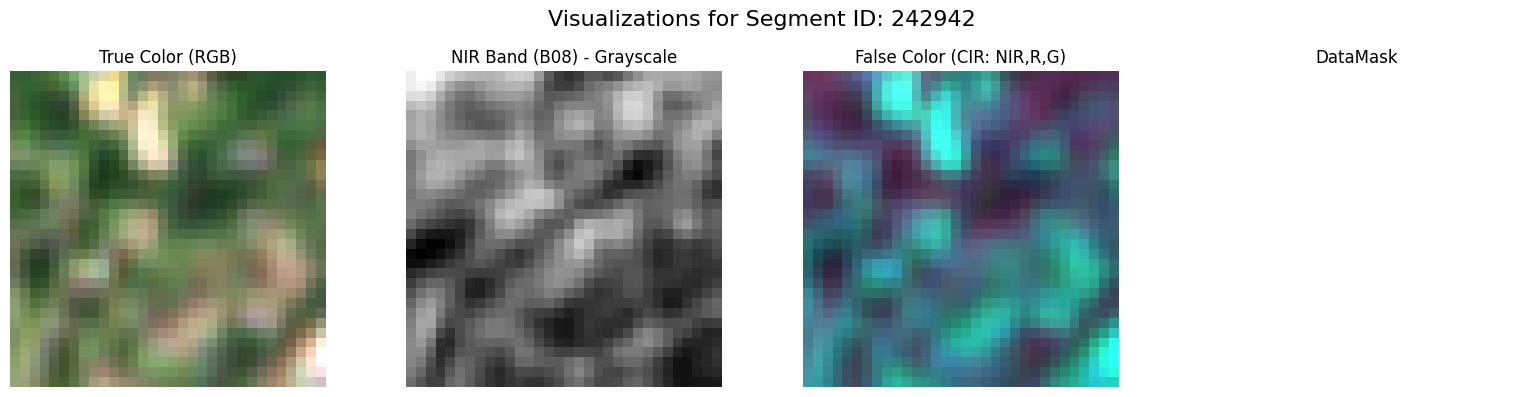


Segment 242941: Loaded array with shape (32, 32, 9)


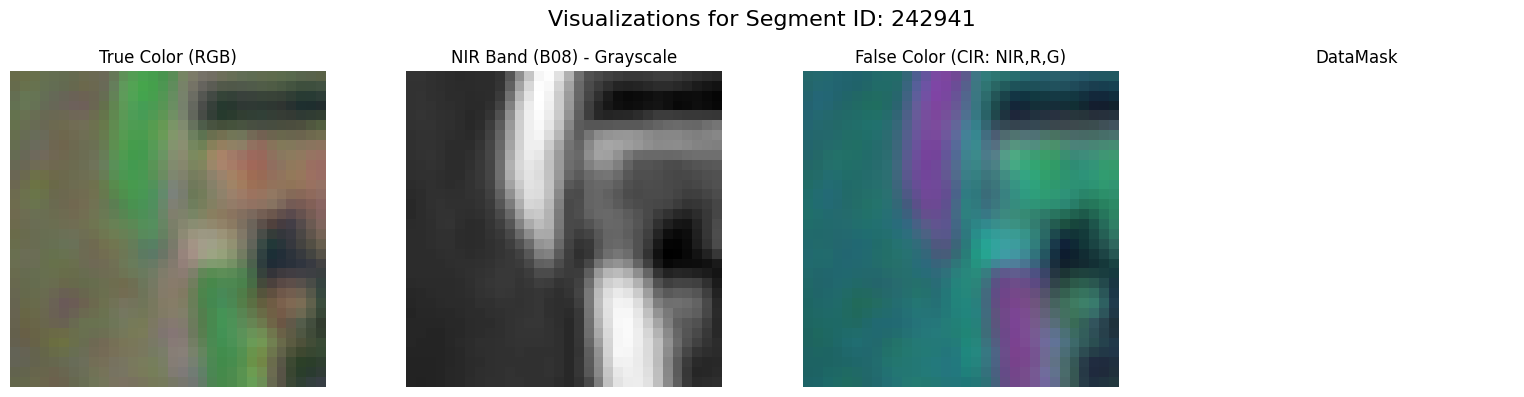


Segment 242940: Loaded array with shape (32, 32, 9)


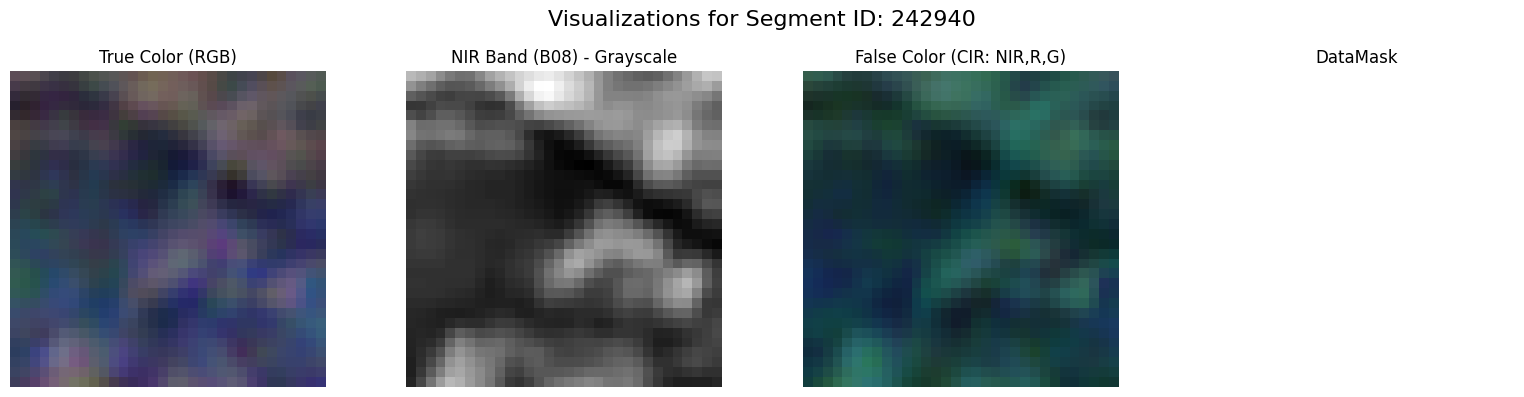


Segment 242939: Loaded array with shape (32, 32, 9)


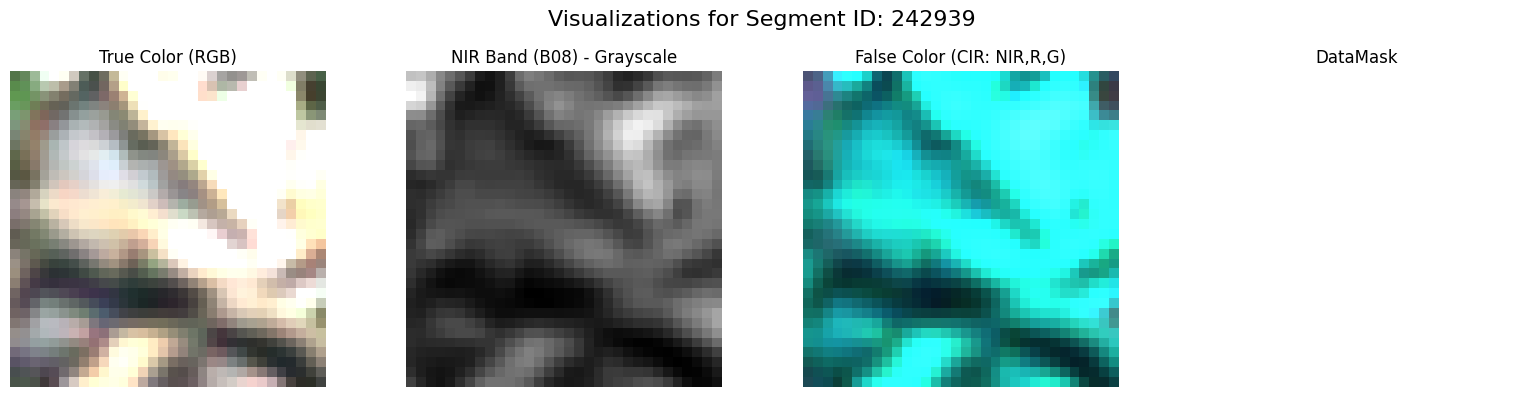


Segment 242938: Loaded array with shape (32, 32, 9)


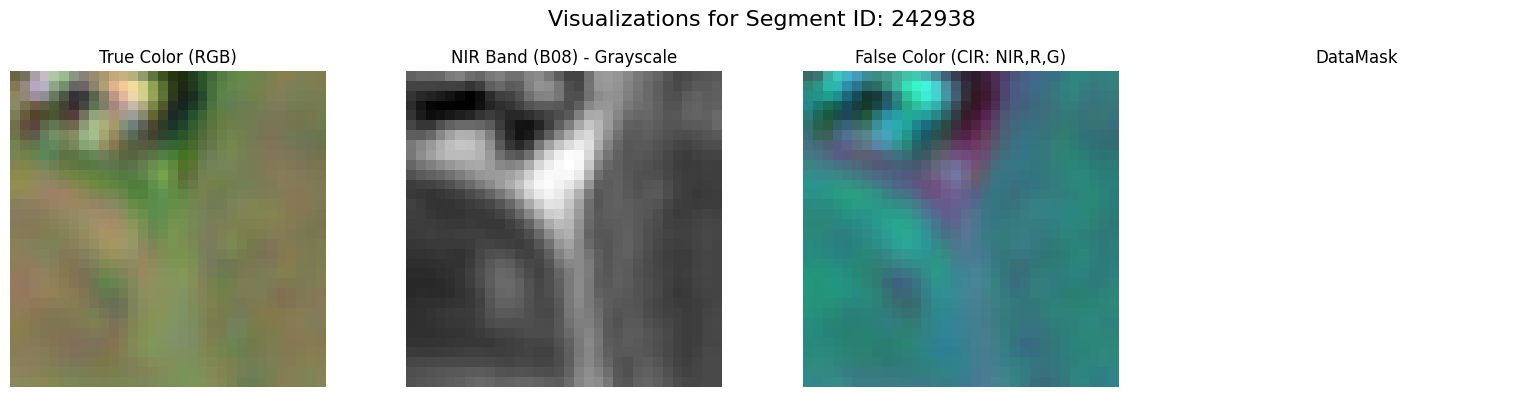


Segment 242937: Loaded array with shape (32, 32, 9)


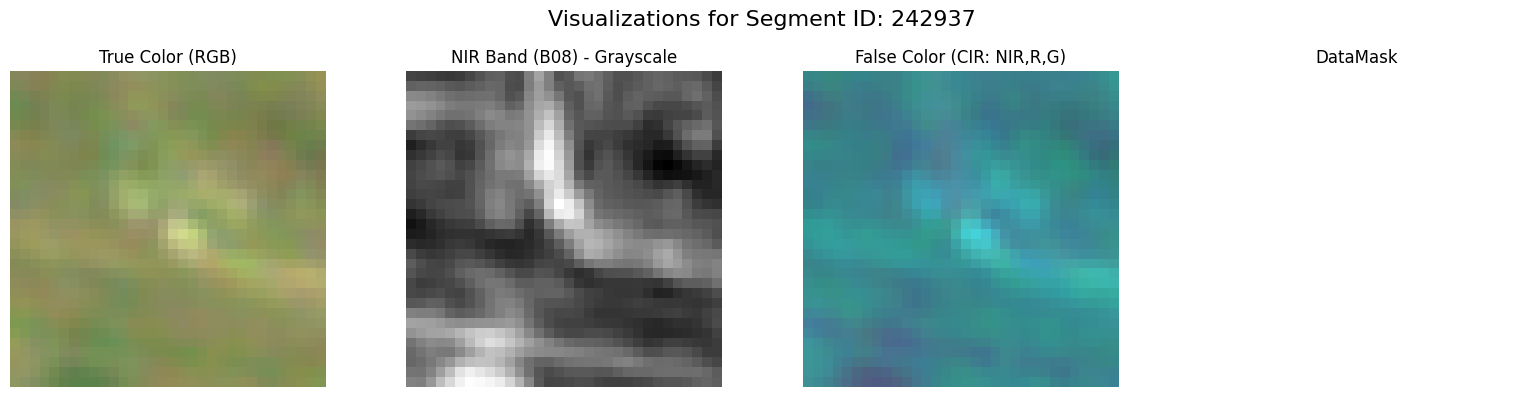


Segment 242936: Loaded array with shape (32, 32, 9)


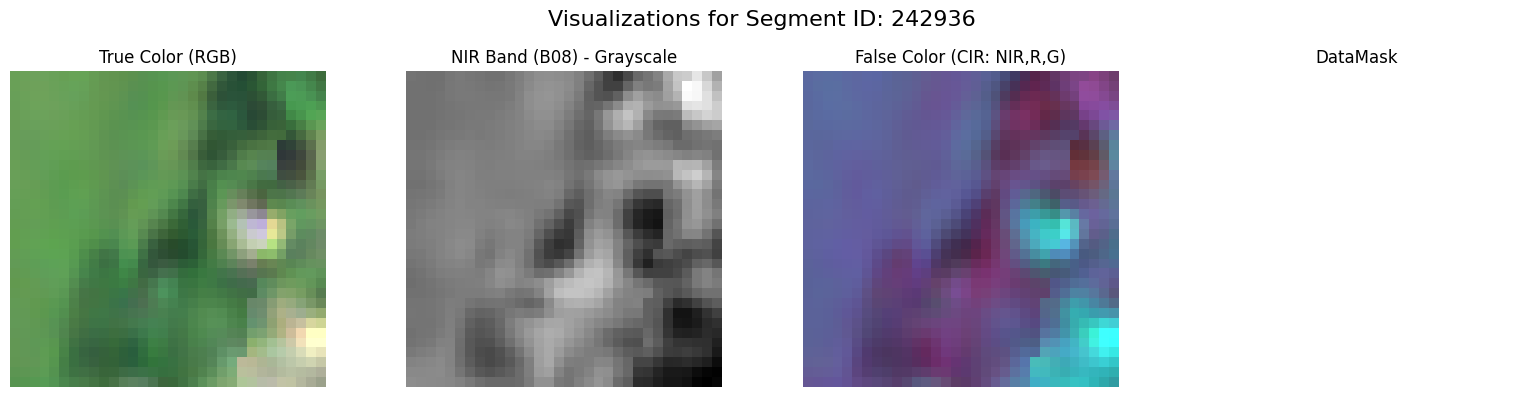


Segment 242935: Loaded array with shape (32, 32, 9)


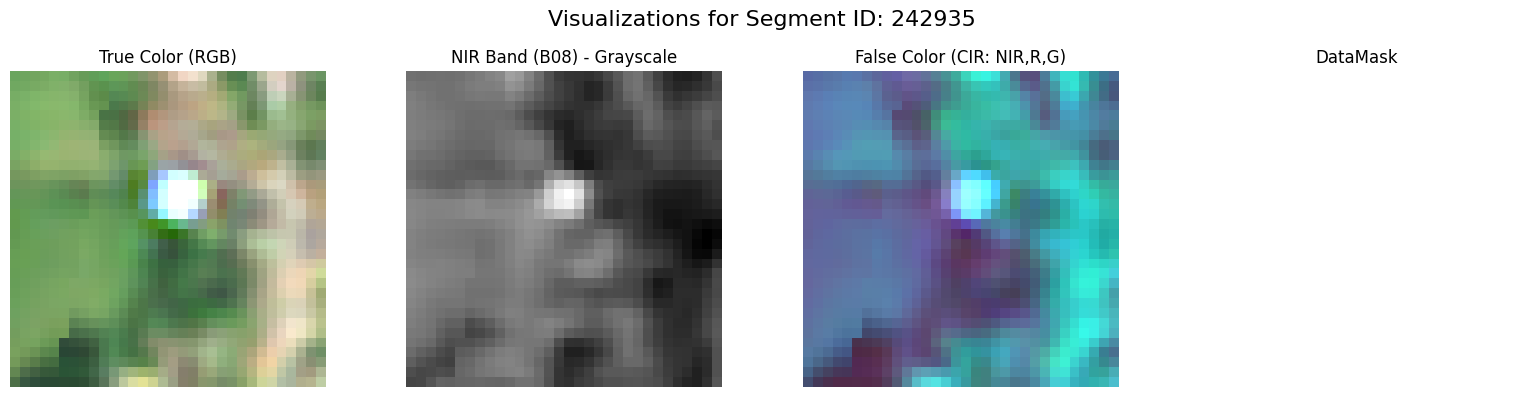


Segment 242934: Loaded array with shape (32, 32, 9)


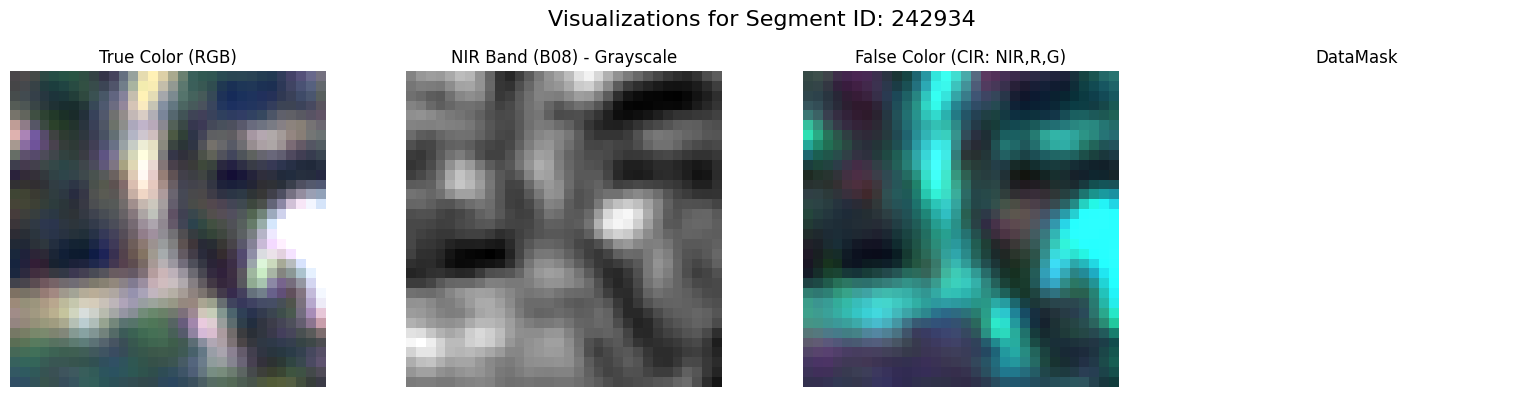


Segment 242933: Loaded array with shape (32, 32, 9)


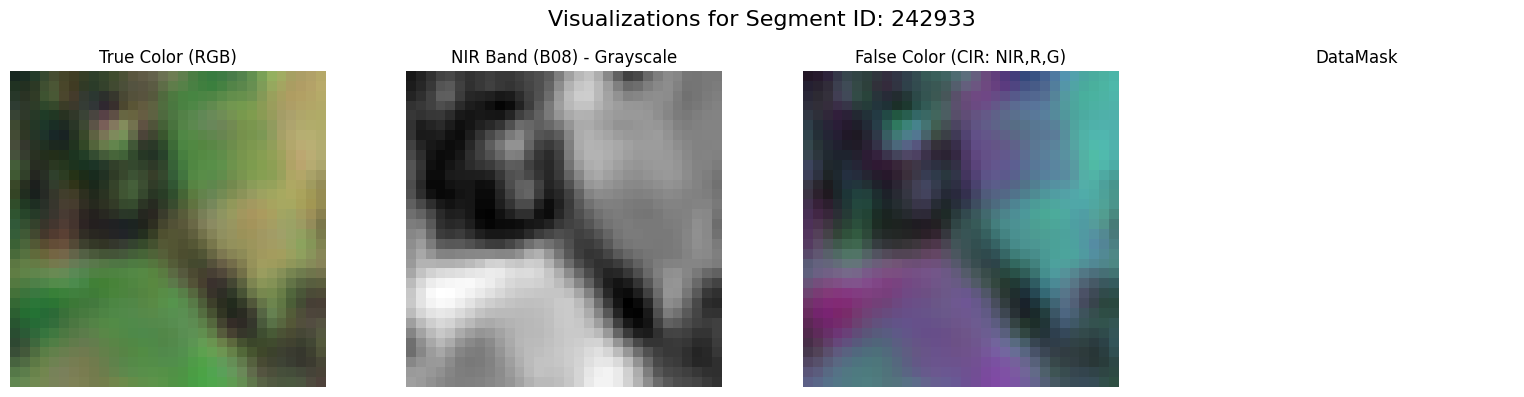


Segment 242932: Loaded array with shape (32, 32, 9)


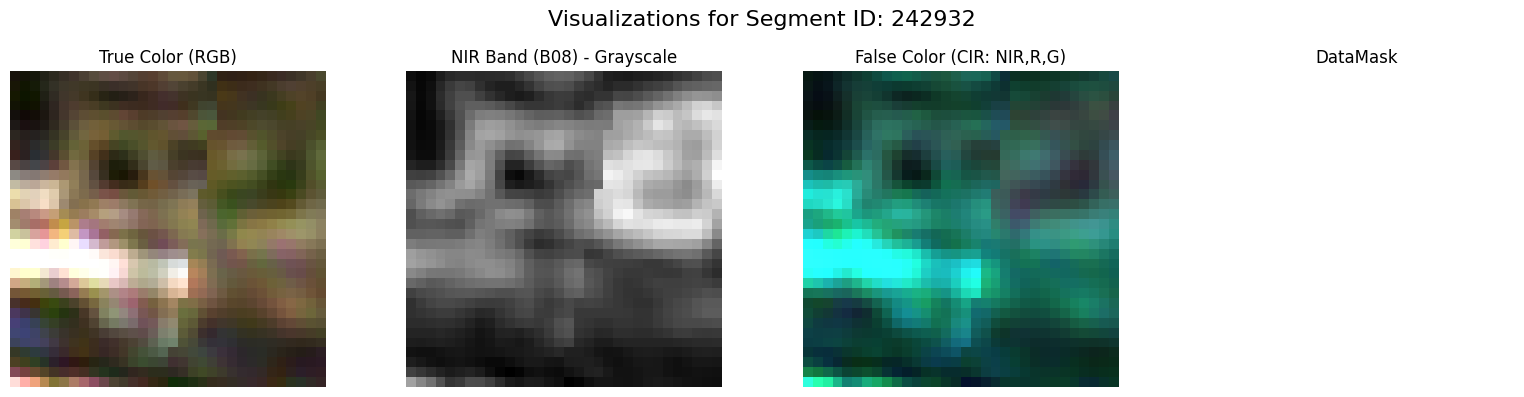


Segment 242931: Loaded array with shape (32, 32, 9)


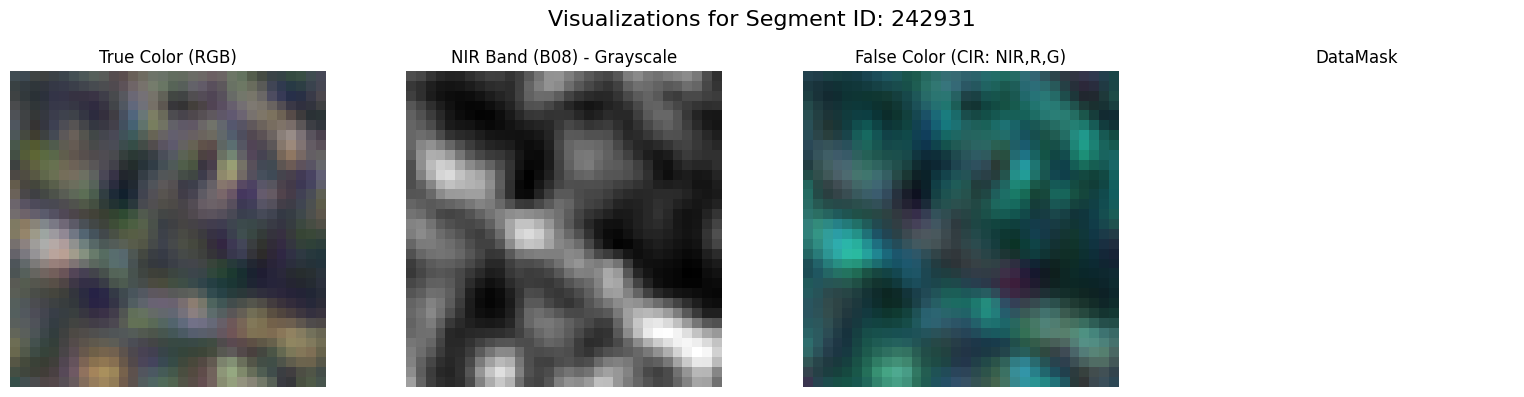


Segment 242930: Loaded array with shape (32, 32, 9)


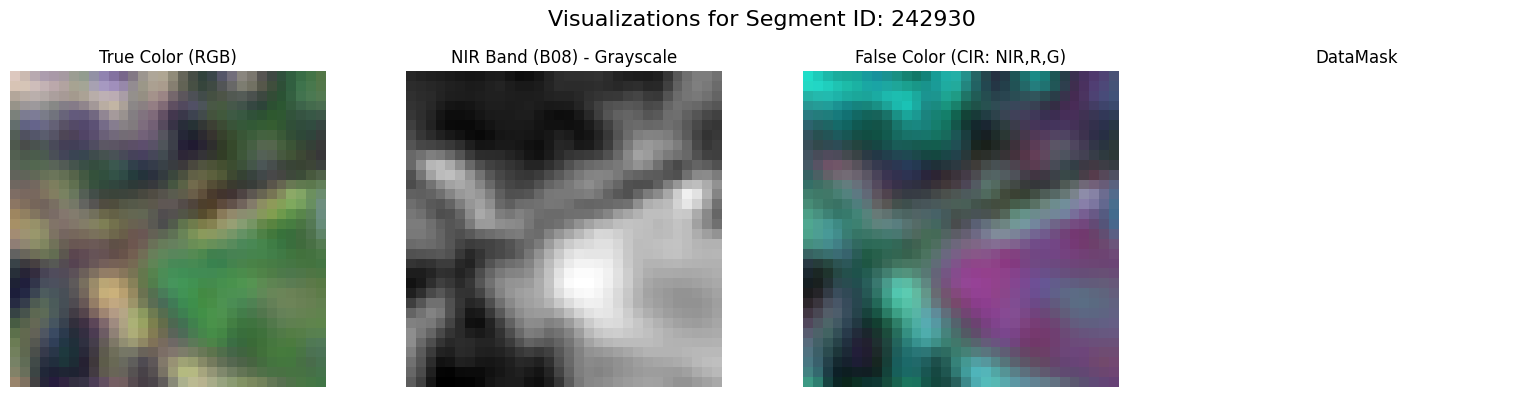


Segment 242929: Loaded array with shape (32, 32, 9)


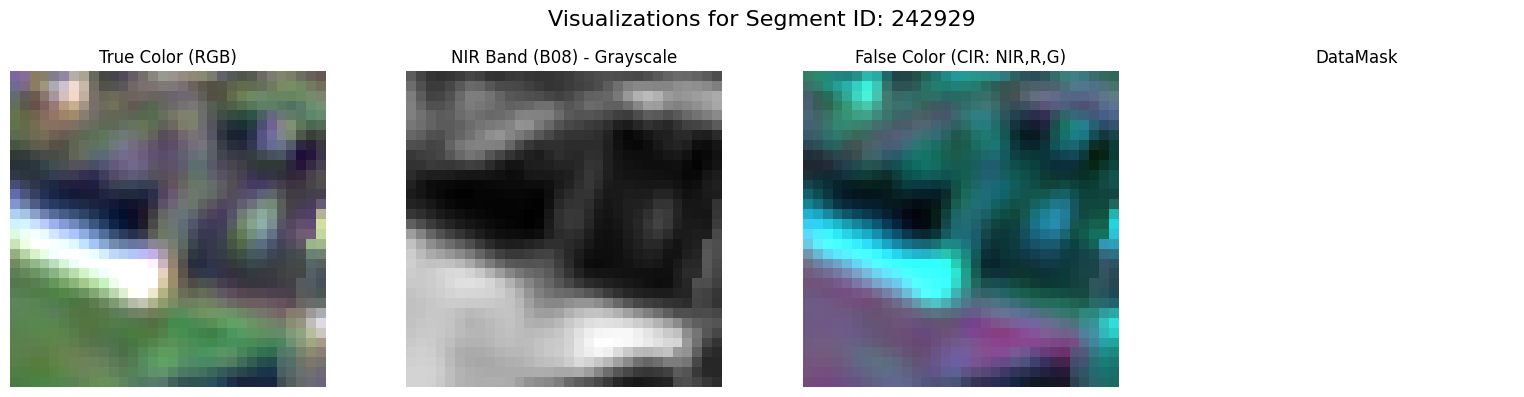


Segment 242928: Loaded array with shape (32, 32, 9)


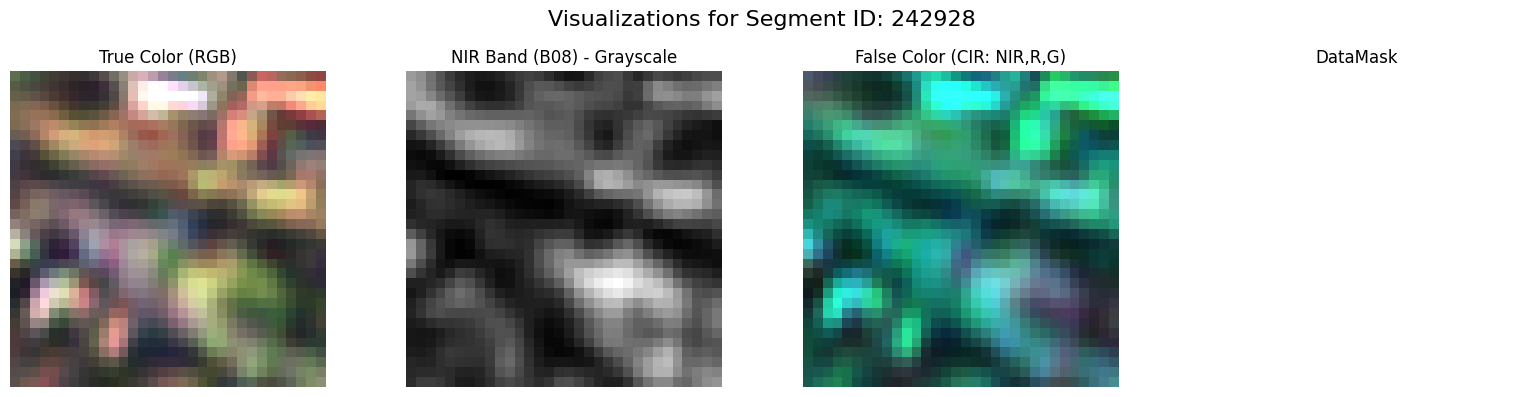


Segment 242927: Loaded array with shape (32, 32, 9)


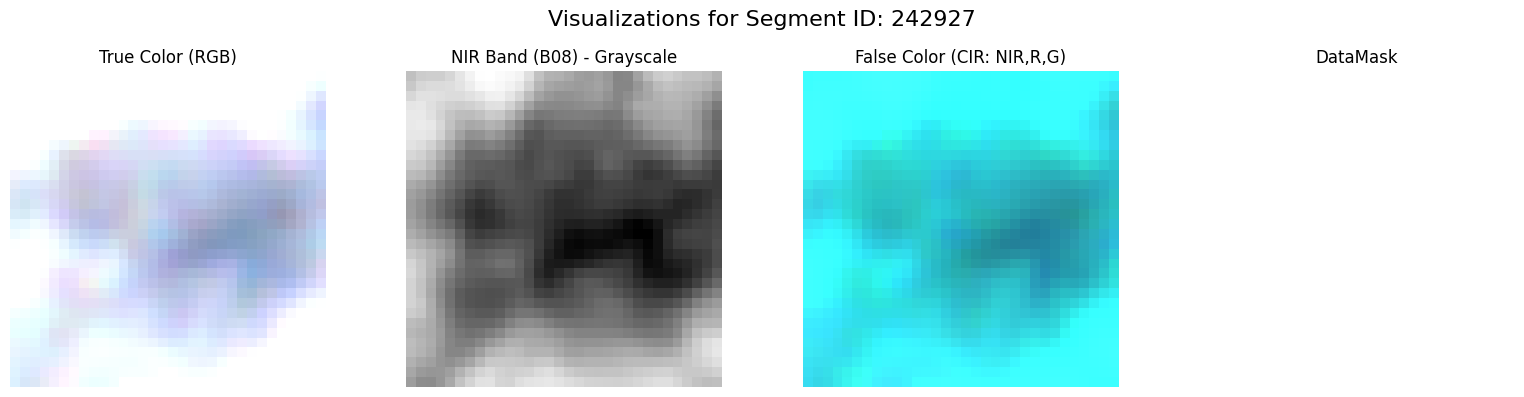


Segment 242926: Loaded array with shape (32, 32, 9)


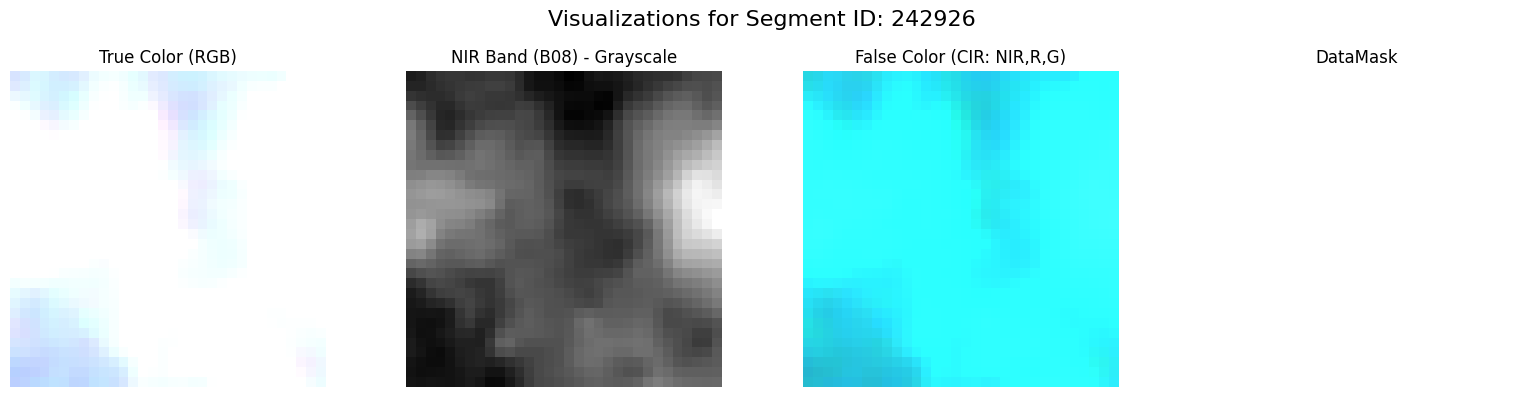


Segment 242925: Loaded array with shape (32, 32, 9)


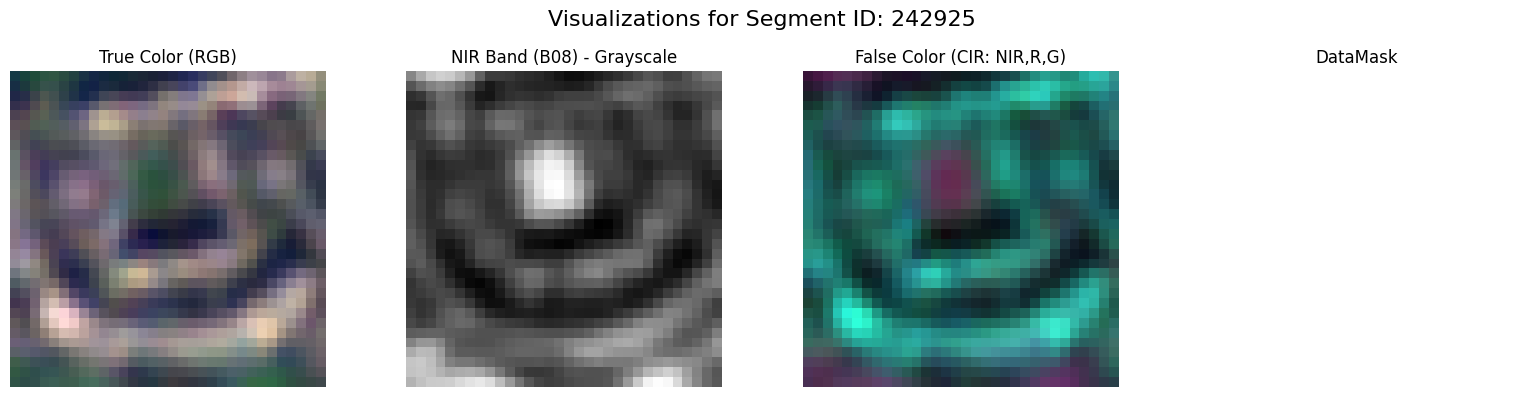


Segment 242924: Loaded array with shape (32, 32, 9)


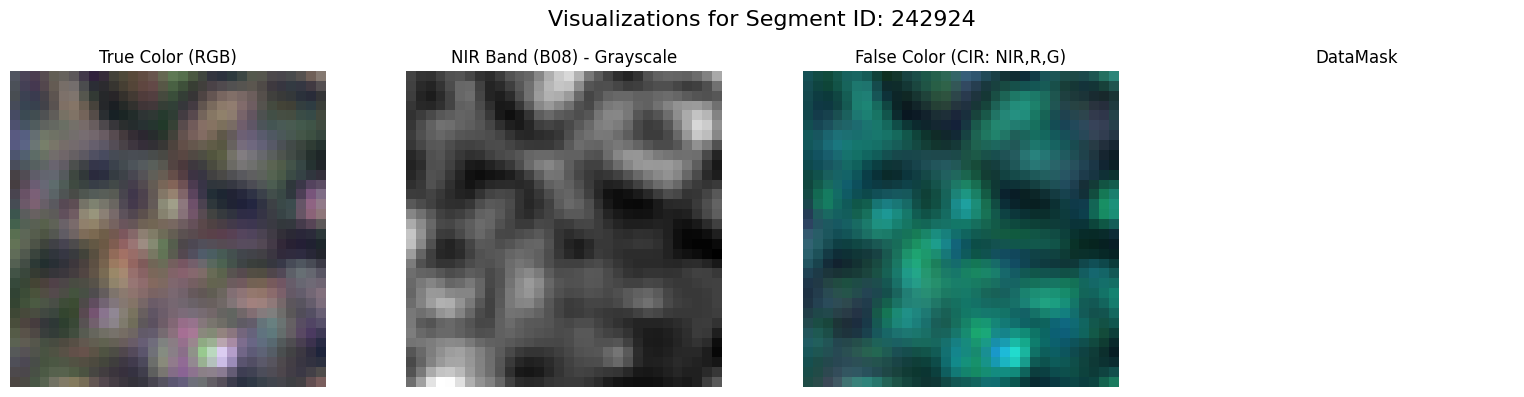


Segment 242923: Loaded array with shape (32, 32, 9)


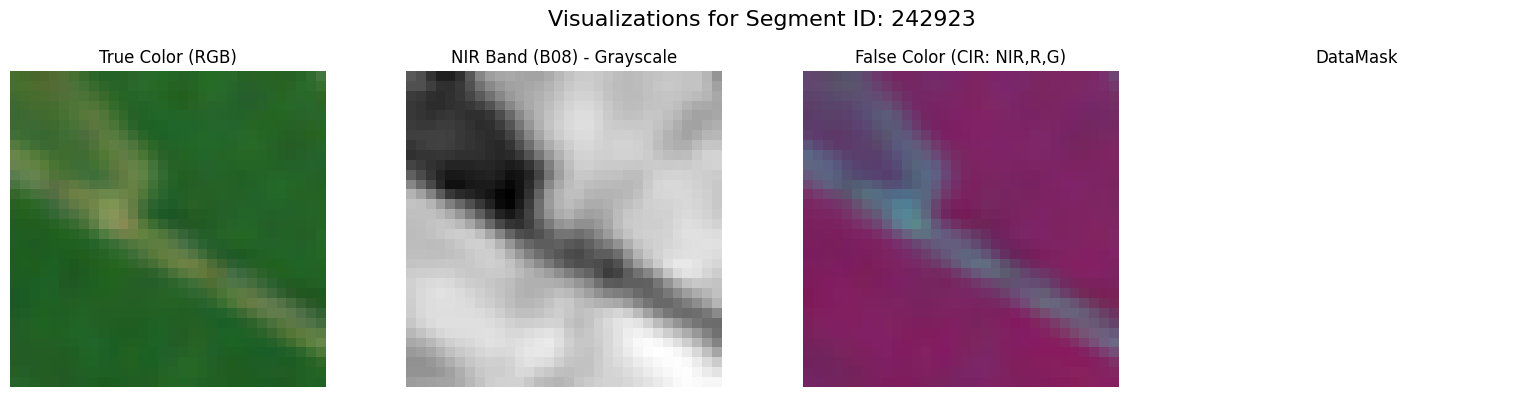


Segment 242922: Loaded array with shape (32, 32, 9)


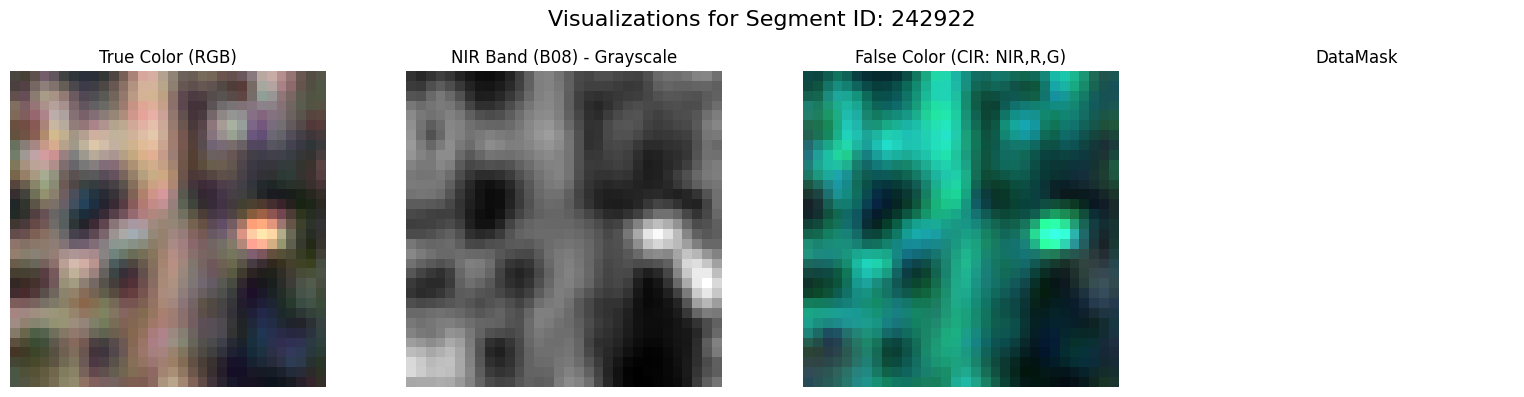


Segment 242921: Loaded array with shape (32, 32, 9)


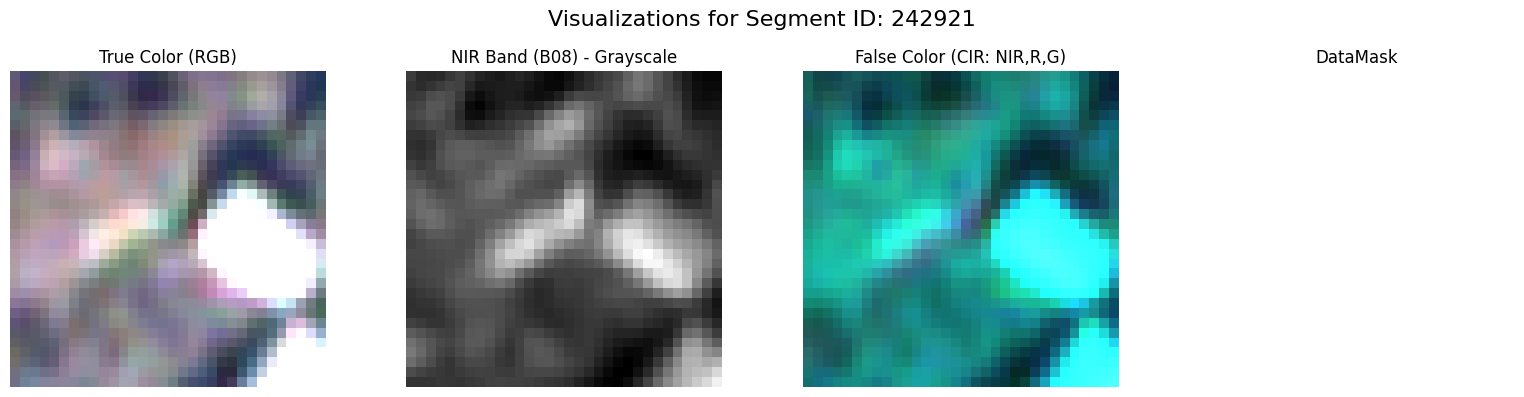


Segment 242920: Loaded array with shape (32, 32, 9)


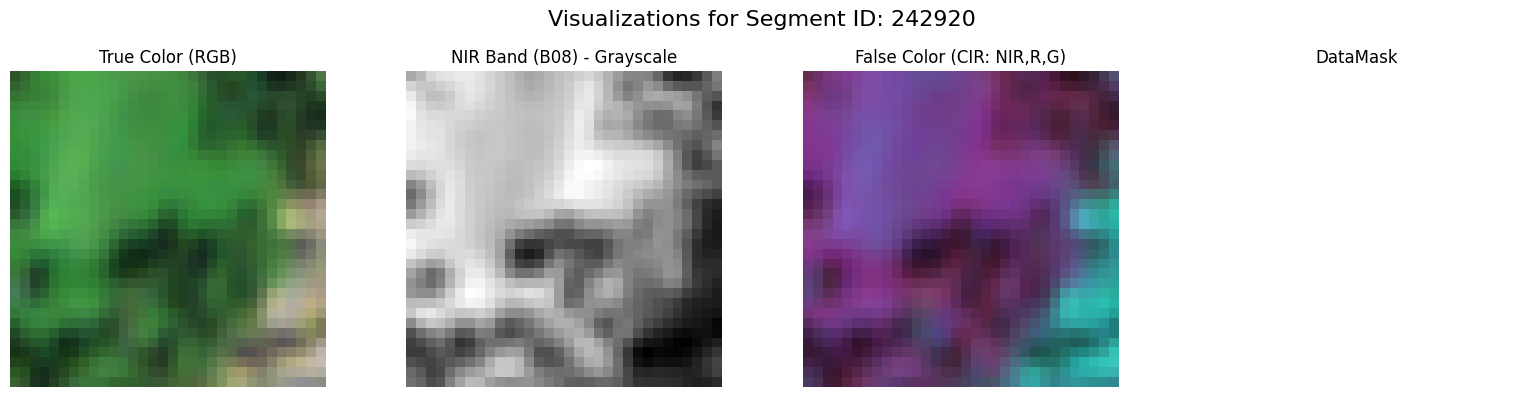


Segment 242919: Loaded array with shape (32, 32, 9)


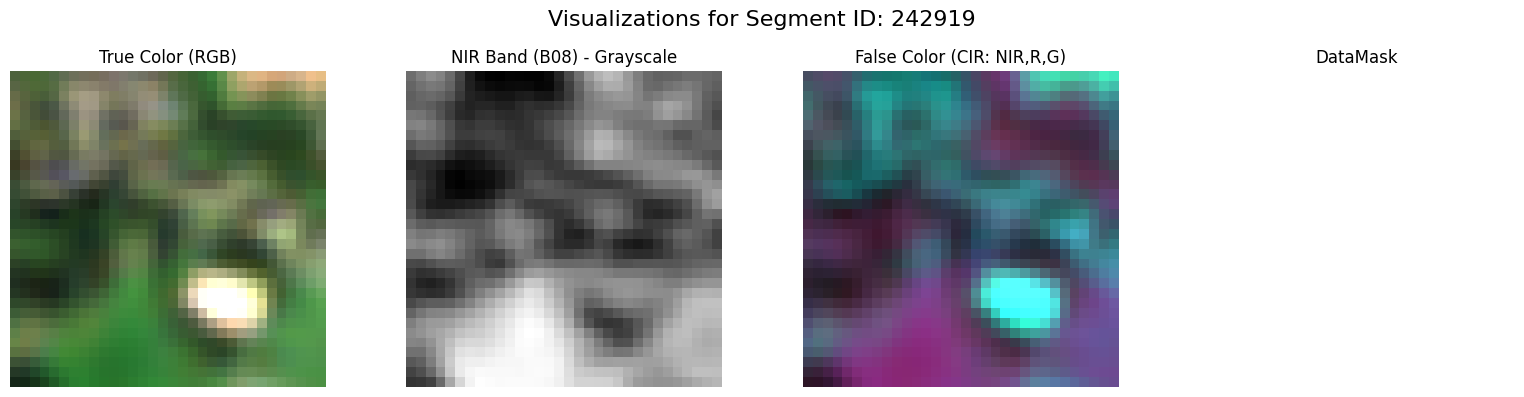


Segment 242918: Loaded array with shape (32, 32, 9)


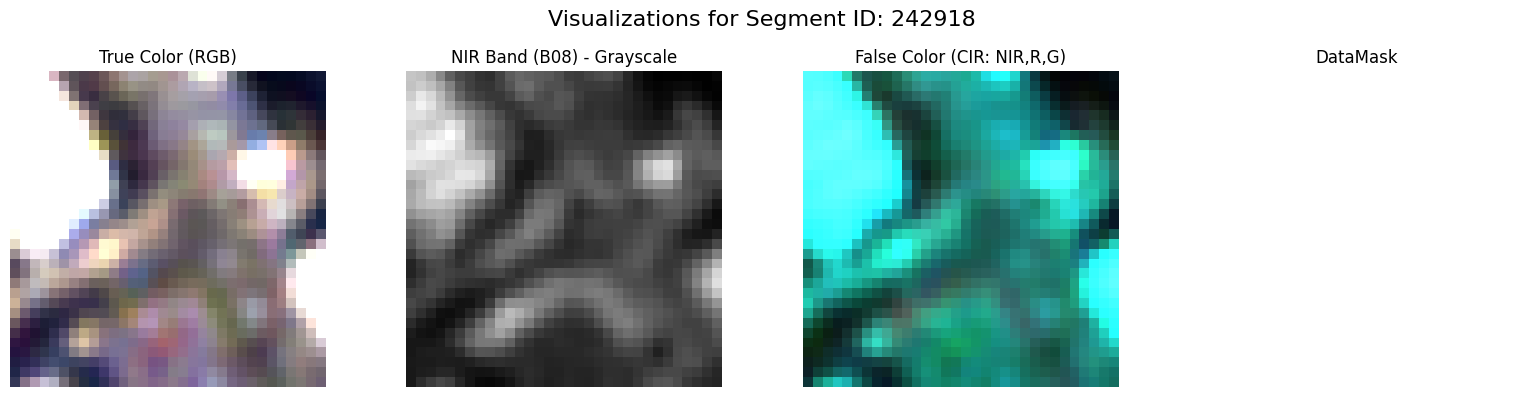


Segment 242917: Loaded array with shape (32, 32, 9)


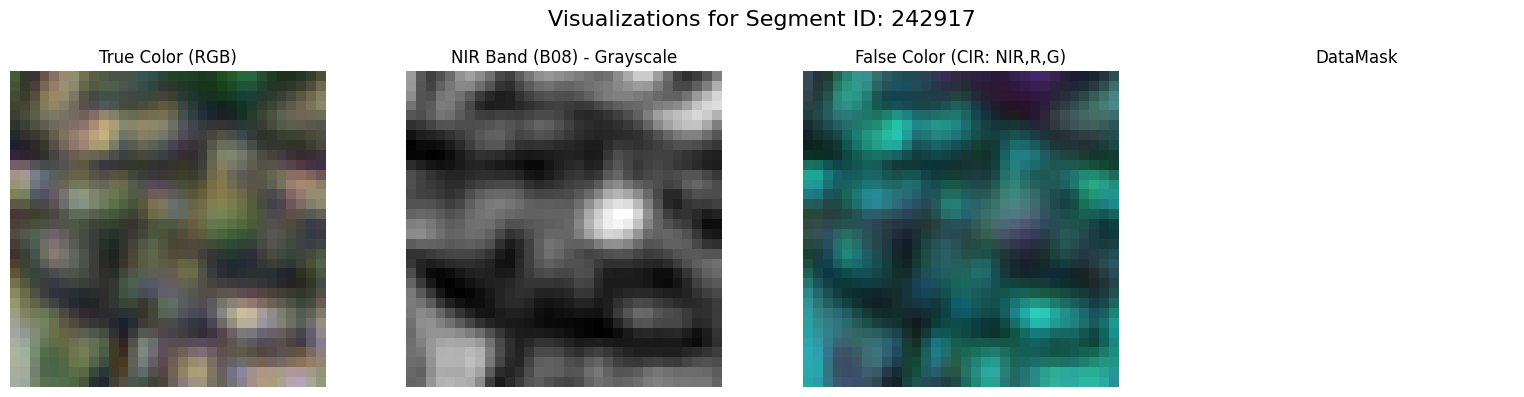


Segment 242916: Loaded array with shape (32, 32, 9)


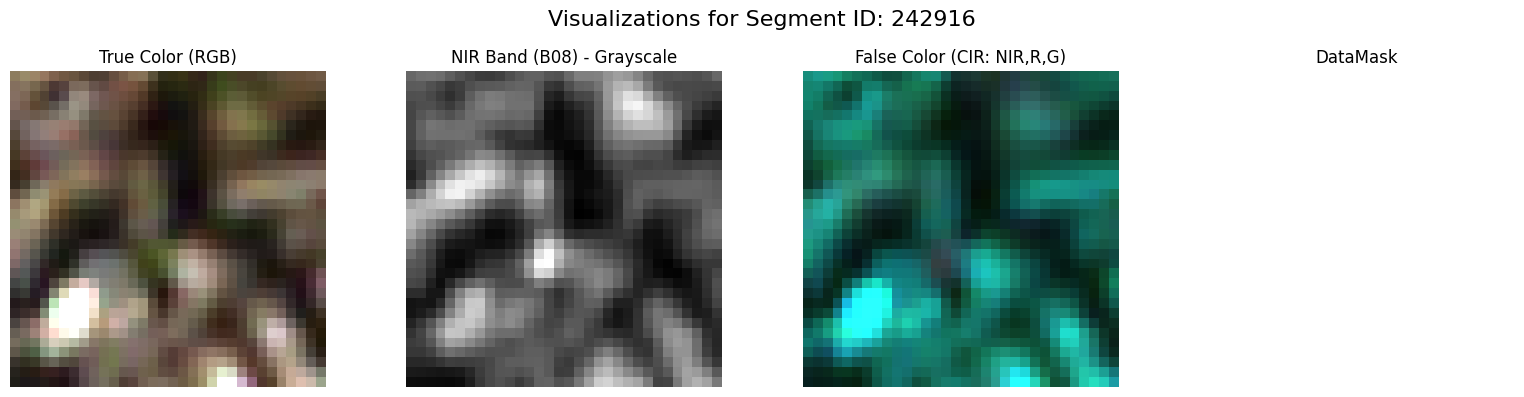


Segment 242915: Loaded array with shape (32, 32, 9)


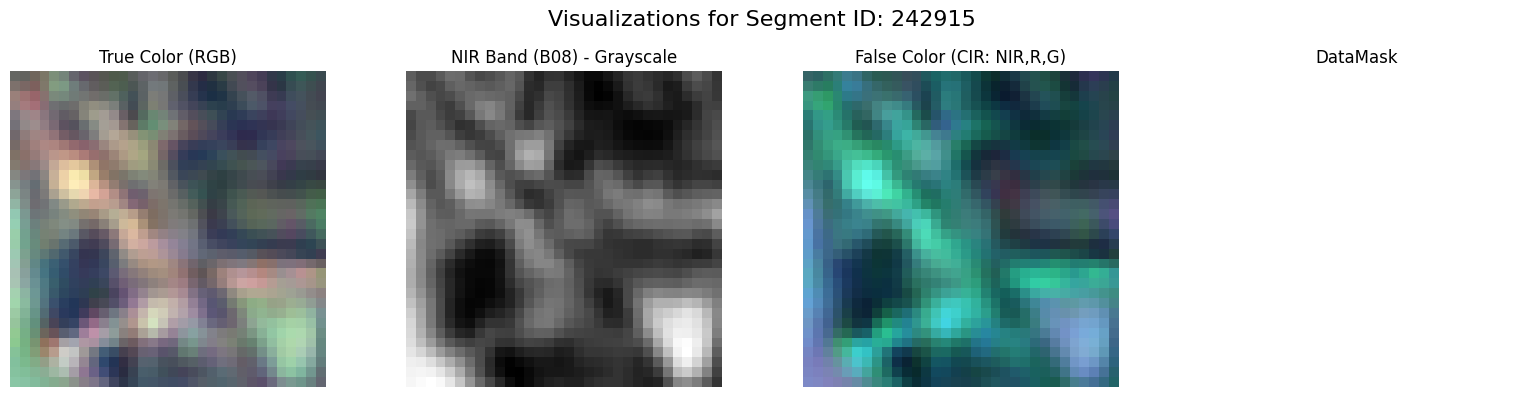


Segment 242914: Loaded array with shape (32, 32, 9)


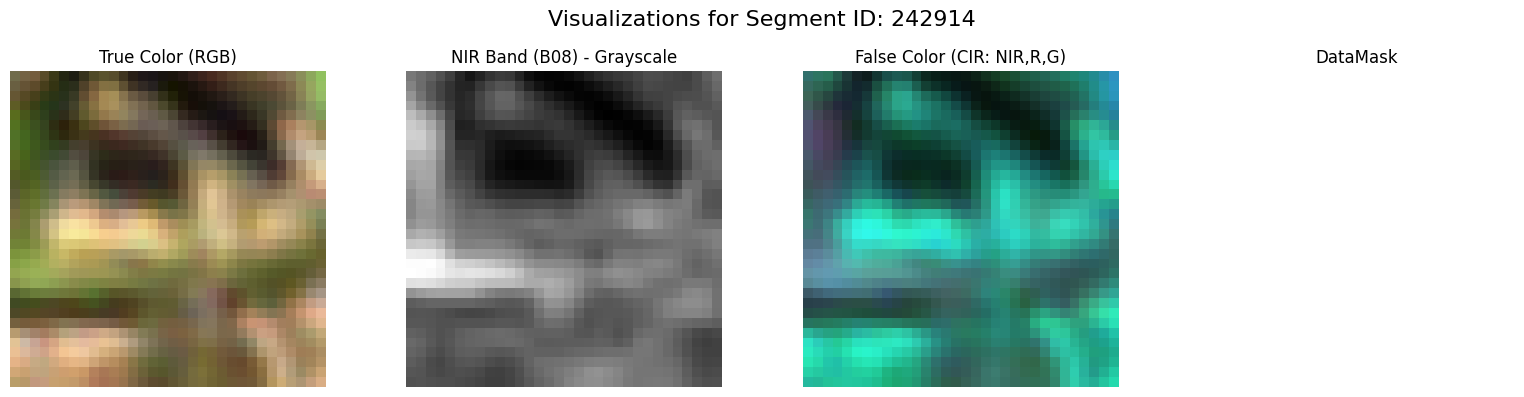


Segment 242913: Loaded array with shape (32, 32, 9)


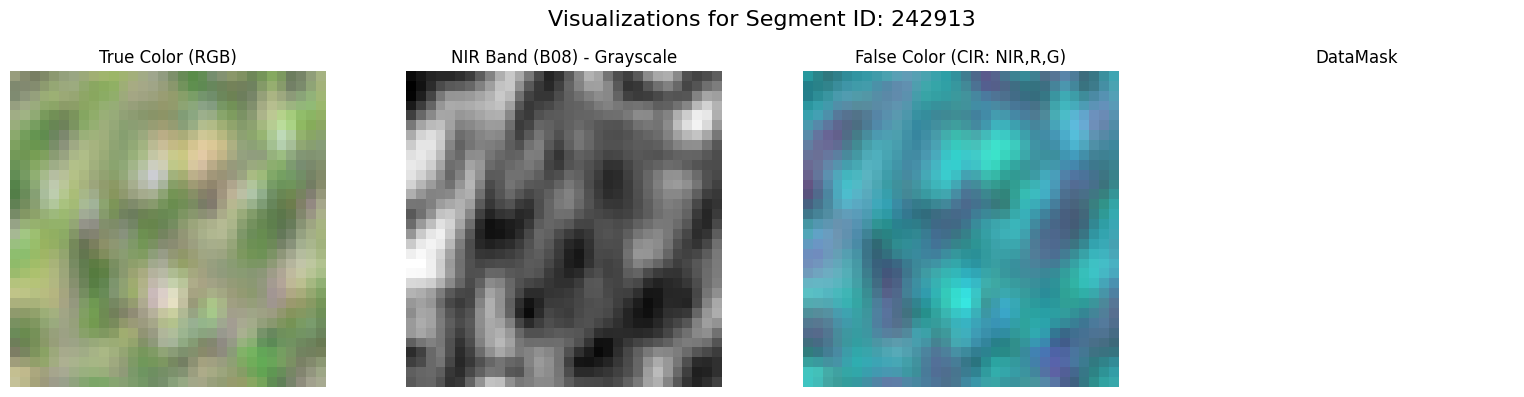

In [3]:
import pandas as pd
import numpy as np
import io
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

# 1. Create your database engine (replace with your actual connection string)

# 2. Query rows that have image data
query = "SELECT id, image_data FROM final_balanced_trail_segments WHERE image_data IS NOT NULL ORDER BY id DESC LIMIT 30" # Limit to 2 for quicker demo
try:
    segments_with_images = pd.read_sql(query, engine)
except Exception as e:
    print(f"Error executing SQL query: {e}")
    raise

if segments_with_images.empty:
    print("No segments with image_data found in the database (or matching the LIMIT).")
else:
    print(f"Found {len(segments_with_images)} segment(s) with images to display.")

    for idx, row in segments_with_images.iterrows():
        segment_id = row['id']
        image_bytes = row['image_data']

        if image_bytes is None:
            print(f"Segment {segment_id} has NULL image_data. Skipping.")
            continue

        try:
            image_array = np.load(io.BytesIO(image_bytes))
            print(f"\nSegment {segment_id}: Loaded array with shape {image_array.shape}")

            if not (image_array.ndim == 3 and image_array.shape[-1] == 9):
                print(f"  Segment {segment_id}: Image array has unexpected shape {image_array.shape}. Skipping visualizations for this segment.")
                continue

            # --- 1. True Color RGB (B04, B03, B02) ---
            # Bands 0, 1, 2 are Red, Green, Blue (already scaled by 8.0)
            rgb_bands = image_array[..., :3]
            true_color_image = np.clip(rgb_bands, 0, 1) # Normalize back to ~0-1

            # --- 2. Grayscale NIR Band (B08) ---
            # Band 5 is NIR (B08), not scaled by 8.0 in evalscript
            nir_band = image_array[..., 5]
            # Normalize NIR band (typically 0-1 reflectance) for display
            nir_gray_image = np.clip(nir_band, 0, 1)
            
            # --- 3. False-Color Composite (CIR: NIR, Red, Green) ---
            # Display R = NIR (band 5), G = Red (band 0), B = Green (band 1)
            
            # NIR band (B08) - already approx 0-1
            nir_for_cir = np.clip(image_array[..., 5], 0, 1)
            # Red band (B04*8.0) - normalize back to approx 0-1
            red_for_cir = np.clip(image_array[..., 0], 0, 1)
            # Green band (B03*8.0) - normalize back to approx 0-1
            green_for_cir = np.clip(image_array[..., 1], 0, 1)
            
            false_color_cir_image = np.stack([nir_for_cir, red_for_cir, green_for_cir], axis=-1)

            # --- 4. Grayscale dataMask ---
            # Band 8 is dataMask (0 for no-data, 1 for data)
            datamask_image = image_array[..., 8] # Values are 0 or 1

            # --- Plotting all visualizations ---
            fig, axs = plt.subplots(1, 4, figsize=(16, 4)) # 1 row, 4 columns of plots
            fig.suptitle(f"Visualizations for Segment ID: {segment_id}", fontsize=16)

            axs[0].imshow(true_color_image)
            axs[0].set_title("True Color (RGB)")
            axs[0].axis('off')

            axs[1].imshow(nir_gray_image, cmap='gray')
            axs[1].set_title("NIR Band (B08) - Grayscale")
            axs[1].axis('off')
            
            axs[2].imshow(false_color_cir_image)
            axs[2].set_title("False Color (CIR: NIR,R,G)")
            axs[2].axis('off')

            axs[3].imshow(datamask_image, cmap='gray', vmin=0, vmax=1) # Ensure correct display for 0-1 mask
            axs[3].set_title("DataMask")
            axs[3].axis('off')
            
            plt.tight_layout(rect=[0, 0, 1, 0.96]) # Adjust layout to make space for suptitle
            plt.show()

        except Exception as e:
            print(f"  Error processing or displaying images for segment {segment_id}: {e}")